# Socio-economic trends study of distribution of heating system and health outcomes in England & Wales

## Visual Analytics Coursework- Full analysis python script

### Username: nk25358

**Research Question:** What socioeconimic factors - occupational class, housing tenure, and age predict whether a household lacks central heating across Local Authorities in England and Wales, and does the absence of heating coorealte with worse self-reported health outcomes between 2011 and 2021?

**Notebook Structure**
1. Setup and imports
2. Load and inspect the raw data
3. Clean and extract the features
4. Merge dataset of 2011
5. Geographic harmonisation (2011-2021)
6. Missing value analysis
7. Bayesian imputation (BayesianRidge via InterativeImputer)
8. Standardised features
9. Dimensionality reduction: PCA
10. Dimensionality reduction: t-SNE
11. Dimensionality reduction: MDS (for comparision)
12. Exporting CSVs

## 1. Setup and imports

In [2]:
#install and import packages
%pip install pandas numpy matplotlib seaborn scikit-learn
%pip install umap-learn
%pip install arviz
%pip install numpy==2.3.0
%pip install tableauhyperapi


print("All packages are installed and imported.")

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
All packages are installed and imported.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, MDS
from sklearn.linear_model import BayesianRidge
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import umap
import arviz as az



print("Packages imported successfully.")

Packages imported successfully.


## 2. Load and inspect the raw data

In [2]:
#loading the dataset

# central heating dataset by LA 2011
path_heat_2011 = '/Users/aanchala/VISA/datasets/central_heating-2011.csv'

# central heating + age dataset by LA 2011
path_heat_age = '/Users/aanchala/VISA/datasets/central_heating-age-2011.csv'

# central heating + tenure dataset by LA 2011
path_heat_tenure = '/Users/aanchala/VISA/datasets/central_heating-tenure.csv'

# health X NS-Sec dataset by LA 2011
path_health_2011 = '/Users/aanchala/VISA/datasets/health-nssec-2011.csv'

# central heating dataset by LA 2021
path_heat_2021 = '/Users/aanchala/VISA/datasets/central_heating-2021.csv'

# health dataset by LA 2021
path_health_2021 = '/Users/aanchala/VISA/datasets/health-2021.csv'

# 2011 files
raw_heat_2011 = pd.read_csv(path_heat_2011)
raw_heat_age = pd.read_csv(path_heat_age)
raw_heat_tenure = pd.read_csv(path_heat_tenure)
raw_health_2011 = pd.read_csv(path_health_2011)

# 2021 files
raw_heat_2021 = pd.read_csv(path_heat_2021)
raw_health_2021 = pd.read_csv(path_health_2021)

print("Datasets loaded successfully.")
print(f' Central heating 2011: {raw_heat_2011.shape}')
print(f' Central heating + age 2011: {raw_heat_age.shape}')
print(f' Central heating + tenure 2011: {raw_heat_tenure.shape}')
print(f' Health 2011: {raw_health_2011.shape}')
print(f' Central heating 2021: {raw_heat_2021.shape}')
print(f' Health 2021: {raw_health_2021.shape}')


Datasets loaded successfully.
 Central heating 2011: (348, 12)
 Central heating + age 2011: (348, 108)
 Central heating + tenure 2011: (348, 273)
 Health 2011: (348, 99)
 Central heating 2021: (331, 16)
 Health 2021: (331, 9)


In [3]:
#check
for name, df in [('Central heating 2011', raw_heat_2011),
                 ('Central heating + age 2011', raw_heat_age),
                 ('Central heating + tenure 2011', raw_heat_tenure),
                 ('Health 2011', raw_health_2011)]:
    print(f'\n----{name}----')
    print('columns:', list(df.columns[:6]), '___')
    print('row 0: ', df.iloc[0, :4].to_dict())

print('\n----Central heating 2021----')
print('columns:', list(raw_heat_2021.columns))
print('row 0: ', raw_heat_2021.iloc[0, :4].to_dict())

print('\n----Health 2021----')
print('columns:', list(raw_health_2021.columns))
print('row 0: ', raw_health_2021.iloc[0, :4].to_dict())


----Central heating 2011----
columns: ['date', 'geography', 'geography code', 'Rural Urban', 'Central Heating: All categories: Type of central heating in household; measures: Value', 'Central Heating: No central heating; measures: Value'] ___
row 0:  {'date': 2011, 'geography': 'Darlington', 'geography code': 'E06000005', 'Rural Urban': 'Total'}

----Central heating + age 2011----
columns: ['date', 'geography', 'geography code', 'Central Heating: All categories: Type of central heating in household; Occupancy rating (rooms): All categories: Occupancy rating (rooms); Age: All categories: Age; measures: Value', 'Central Heating: All categories: Type of central heating in household; Occupancy rating (rooms): All categories: Occupancy rating (rooms); Age: Age 0 to 15; measures: Value', 'Central Heating: All categories: Type of central heating in household; Occupancy rating (rooms): All categories: Occupancy rating (rooms); Age: Age 16 to 24; measures: Value'] ___
row 0:  {'date': 2011, 'g

## 3. Clean and extract the features

In [4]:

# ------- FILE 1: central heating dataset by LA 2011 ------

total = raw_heat_2011.iloc[:, 4].astype(float)
no_heat = raw_heat_2011.iloc[:, 5].astype(float)
with_heat = total - no_heat

heat_2011 = pd.DataFrame()
heat_2011['la_code']           = raw_heat_2011['geography code']
heat_2011['la_name']           = raw_heat_2011['geography']
heat_2011['pct_no_heat_2011']   = (no_heat   / total * 100).replace([np.inf,-np.inf], np.nan)
heat_2011['pct_with_heat_2011'] = (with_heat / total * 100).replace([np.inf,-np.inf], np.nan)

# Raw counts (for harmonisation only)
heat_2011['raw_total_hh']    = total
heat_2011['raw_no_heat']     = no_heat
heat_2011['raw_with_heat']   = with_heat

print(f'Central Heating 2011 cleaned: {heat_2011.shape}')
print(heat_2011.head(3).to_string())
print(f'\npct_no_heat_2011:   mean={heat_2011["pct_no_heat_2011"].mean():.2f}%  max={heat_2011["pct_no_heat_2011"].max():.2f}%')
print(f'pct_with_heat_2011: mean={heat_2011["pct_with_heat_2011"].mean():.2f}%  min={heat_2011["pct_with_heat_2011"].min():.2f}%')

Central Heating 2011 cleaned: (348, 7)
     la_code        la_name  pct_no_heat_2011  pct_with_heat_2011  raw_total_hh  raw_no_heat  raw_with_heat
0  E06000005     Darlington          1.744161           98.255839       46670.0        814.0        45856.0
1  E06000047  County Durham          0.834663           99.165337      223803.0       1868.0       221935.0
2  E06000001     Hartlepool          1.434436           98.565564       40434.0        580.0        39854.0

pct_no_heat_2011:   mean=2.61%  max=26.29%
pct_with_heat_2011: mean=97.39%  min=73.71%


In [5]:
# ----- FILE 2: CentralHeating + Age 2011 by LA --------
#   without heat - age groups 

age_groups = ['0_15', '16_24', '25_34', '35_49', '50_64', '65plus']

# Column pairs: (no_heat_cols, total_cols) for each age group
age_index_map = {
    '0_15':   (39, 4),
    '16_24':  (40, 5),
    '25_34':  (41, 6),
    '35_49':  (42, 7),
    '50_64':  (43, 8),
    '65plus': (44, 9),
}

heat_age = pd.DataFrame()
heat_age['la_code'] = raw_heat_age['geography code']

for group, (no_heat_idx, total_idx) in age_index_map.items():
    numerator   = raw_heat_age.iloc[:, no_heat_idx]
    denominator = raw_heat_age.iloc[:, total_idx]
    pct = (numerator / denominator * 100).replace([np.inf, -np.inf], np.nan)
    heat_age[f'pct_no_heat_age_{group}_2011'] = pct
    heat_age[f'raw_no_heat_age_{group}'] = raw_heat_age.iloc[:, no_heat_idx]
    heat_age[f'raw_total_age_{group}']   = raw_heat_age.iloc[:, total_idx]

print(f'Heating+Age 2011 cleaned: {heat_age.shape}')
print('Columns:', heat_age.columns.tolist())
print(heat_age.head(3).to_string())

print('\nValue ranges (should all be 0-100):')
for col in heat_age.columns[1:]:
    print(f'  {col}: {heat_age[col].min():.2f} – {heat_age[col].max():.2f}')

Heating+Age 2011 cleaned: (348, 19)
Columns: ['la_code', 'pct_no_heat_age_0_15_2011', 'raw_no_heat_age_0_15', 'raw_total_age_0_15', 'pct_no_heat_age_16_24_2011', 'raw_no_heat_age_16_24', 'raw_total_age_16_24', 'pct_no_heat_age_25_34_2011', 'raw_no_heat_age_25_34', 'raw_total_age_25_34', 'pct_no_heat_age_35_49_2011', 'raw_no_heat_age_35_49', 'raw_total_age_35_49', 'pct_no_heat_age_50_64_2011', 'raw_no_heat_age_50_64', 'raw_total_age_50_64', 'pct_no_heat_age_65plus_2011', 'raw_no_heat_age_65plus', 'raw_total_age_65plus']
     la_code  pct_no_heat_age_0_15_2011  raw_no_heat_age_0_15  raw_total_age_0_15  pct_no_heat_age_16_24_2011  raw_no_heat_age_16_24  raw_total_age_16_24  pct_no_heat_age_25_34_2011  raw_no_heat_age_25_34  raw_total_age_25_34  pct_no_heat_age_35_49_2011  raw_no_heat_age_35_49  raw_total_age_35_49  pct_no_heat_age_50_64_2011  raw_no_heat_age_50_64  raw_total_age_50_64  pct_no_heat_age_65plus_2011  raw_no_heat_age_65plus  raw_total_age_65plus
0  E06000005                  

In [ ]:
# ----- FILE 3: Central heating + Tenure 2011 by LA -----
# what tenure that lacks heating
# and tenure composition (what % of LA is each tenure)
# which accomodation types are most vulnerable

total = raw_heat_tenure.iloc[:, 3].astype(float)
no_heat_owned    = raw_heat_tenure.iloc[:, 14].astype(float)
no_heat_social   = raw_heat_tenure.iloc[:, 17].astype(float)
no_heat_private  = raw_heat_tenure.iloc[:, 20].astype(float)
has_heat_owned   = raw_heat_tenure.iloc[:, 24].astype(float)
has_heat_social  = raw_heat_tenure.iloc[:, 27].astype(float)
has_heat_private = raw_heat_tenure.iloc[:, 30].astype(float)

heat_tenure = pd.DataFrame()
heat_tenure['la_code'] = raw_heat_tenure['geography code']

# % within each tenure that lacks heating
heat_tenure['pct_owned_no_heat_2011']   = (no_heat_owned   / (no_heat_owned   + has_heat_owned)   * 100).replace([np.inf,-np.inf], np.nan)
heat_tenure['pct_social_no_heat_2011']  = (no_heat_social  / (no_heat_social  + has_heat_social)  * 100).replace([np.inf,-np.inf], np.nan)
heat_tenure['pct_private_no_heat_2011'] = (no_heat_private / (no_heat_private + has_heat_private) * 100).replace([np.inf,-np.inf], np.nan)

# % of LA households are each tenure
heat_tenure['pct_owned_2011']   = ((no_heat_owned   + has_heat_owned)   / total * 100).replace([np.inf,-np.inf], np.nan)
heat_tenure['pct_social_2011']  = ((no_heat_social  + has_heat_social)  / total * 100).replace([np.inf,-np.inf], np.nan)
heat_tenure['pct_private_2011'] = ((no_heat_private + has_heat_private) / total * 100).replace([np.inf,-np.inf], np.nan)

# Raw counts for harmonisation
heat_tenure['raw_total_hh_tenure']  = total
heat_tenure['raw_no_heat_owned']    = no_heat_owned
heat_tenure['raw_no_heat_social']   = no_heat_social
heat_tenure['raw_no_heat_private']  = no_heat_private
heat_tenure['raw_has_heat_owned']   = has_heat_owned
heat_tenure['raw_has_heat_social']  = has_heat_social
heat_tenure['raw_has_heat_private'] = has_heat_private

print(f'Central heating + Tenure 2011 cleaned: {heat_tenure.shape}')
print(f'Columns: {heat_tenure.columns.tolist()}')
print(heat_tenure.head(3).to_string())

print('\nVulnerability ranges (should make private > owned > social):')
for col in ['pct_owned_no_heat_2011','pct_social_no_heat_2011','pct_private_no_heat_2011']:
    print(f'  {col}: mean={heat_tenure[col].mean():.2f}%  max={heat_tenure[col].max():.2f}%')

Central heating + Tenure 2011 cleaned: (348, 14)
Columns: ['la_code', 'pct_owned_no_heat_2011', 'pct_social_no_heat_2011', 'pct_private_no_heat_2011', 'pct_owned_2011', 'pct_social_2011', 'pct_private_2011', 'raw_total_hh_tenure', 'raw_no_heat_owned', 'raw_no_heat_social', 'raw_no_heat_private', 'raw_has_heat_owned', 'raw_has_heat_social', 'raw_has_heat_private']
     la_code  pct_owned_no_heat_2011  pct_social_no_heat_2011  pct_private_no_heat_2011  pct_owned_2011  pct_social_2011  pct_private_2011  raw_total_hh_tenure  raw_no_heat_owned  raw_no_heat_social  raw_no_heat_private  raw_has_heat_owned  raw_has_heat_social  raw_has_heat_private
0  E06000005                1.801950                 0.567239                  2.495822       65.281766        15.487465         19.230769              46670.0              549.0                41.0                224.0             29918.0               7187.0                8751.0
1  E06000047                0.880712                 0.324416       

In [7]:
# ----- FILE 4: Health × NS-SeC 2011 --------
# Extracts socioeconomic gradient: top class (managerial) vs bottom (routine + never worked)
# and health outcomes for both

total_pop = raw_health_2011.iloc[:, 3].astype(float)

# occupational class distribution
higher_mgr     = raw_health_2011.iloc[:, 4].astype(float)   # NS-SeC 1: top
routine_occ    = raw_health_2011.iloc[:, 12].astype(float)  # NS-SeC 7: bottom
never_worked   = raw_health_2011.iloc[:, 13].astype(float)  # NS-SeC 8: most vulnerable

# health outcomes 
very_good_all  = raw_health_2011.iloc[:, 19].astype(float)
good_all       = raw_health_2011.iloc[:, 35].astype(float)
bad_all        = raw_health_2011.iloc[:, 67].astype(float)
very_bad_all   = raw_health_2011.iloc[:, 83].astype(float)

# bad health within bottom class (routine + never worked)
bad_routine    = raw_health_2011.iloc[:, 76].astype(float)  # bad health, NS-SeC 7
bad_never      = raw_health_2011.iloc[:, 77].astype(float)  # bad health, NS-SeC 8

health = pd.DataFrame()
health['la_code'] = raw_health_2011['geography code']

# Class composition
health['pct_higher_mgr_2011']   = (higher_mgr   / total_pop * 100).replace([np.inf,-np.inf], np.nan)
health['pct_routine_occ_2011'] = (routine_occ / total_pop * 100).replace([np.inf,-np.inf], np.nan)
health['pct_never_worked_2011'] = (never_worked / total_pop * 100).replace([np.inf,-np.inf], np.nan)

# Health outcomes (overall)
health['pct_good_health_2011'] = ((very_good_all + good_all) / total_pop * 100).replace([np.inf,-np.inf], np.nan)
health['pct_bad_health_2011']  = ((bad_all + very_bad_all)   / total_pop * 100).replace([np.inf,-np.inf], np.nan)

# Bad health within bottom class
health['pct_bad_health_routine_2011'] = (bad_routine / routine_occ * 100).replace([np.inf,-np.inf], np.nan)
health['pct_bad_health_never_2011'] = (bad_never / never_worked * 100).replace([np.inf,-np.inf], np.nan)

health['raw_total_pop']    = total_pop
health['raw_higher_mgr']   = higher_mgr
health['raw_routine_occ']  = routine_occ
health['raw_never_worked'] = never_worked
health['raw_good_health']  = very_good_all + good_all
health['raw_bad_health']   = bad_all + very_bad_all

print(f'Health 2011 cleaned: {health.shape}')
print(f'Columns: {health.columns.tolist()}')
print(health.head(3).to_string())

print('\nKey ranges:')
print(f'  pct_higher_mgr_2011 (top class):   mean={health["pct_higher_mgr_2011"].mean():.2f}%')
print(f'  pct_routine_occ_2011 (bottom):     mean={health["pct_routine_occ_2011"].mean():.2f}%')
print(f'  pct_good_health_2011:              mean={health["pct_good_health_2011"].mean():.2f}%')
print(f'  pct_bad_health_2011:               mean={health["pct_bad_health_2011"].mean():.2f}%')
print(f'  pct_bad_health_routine_2011:       mean={health["pct_bad_health_routine_2011"].mean():.2f}%  ← gradient')

Health 2011 cleaned: (348, 14)
Columns: ['la_code', 'pct_higher_mgr_2011', 'pct_routine_occ_2011', 'pct_never_worked_2011', 'pct_good_health_2011', 'pct_bad_health_2011', 'pct_bad_health_routine_2011', 'pct_bad_health_never_2011', 'raw_total_pop', 'raw_higher_mgr', 'raw_routine_occ', 'raw_never_worked', 'raw_good_health', 'raw_bad_health']
     la_code  pct_higher_mgr_2011  pct_routine_occ_2011  pct_never_worked_2011  pct_good_health_2011  pct_bad_health_2011  pct_bad_health_routine_2011  pct_bad_health_never_2011  raw_total_pop  raw_higher_mgr  raw_routine_occ  raw_never_worked  raw_good_health  raw_bad_health
0  E06000005             8.192650             13.709479               6.302939             75.672763             7.111309                     9.229192                  10.241636        85357.0          6993.0          11702.0            5380.0          64592.0          6070.0
1  E06000047             6.924502             16.702566               6.110173             71.361385    

In [8]:
# ----- FILE 5: Central heating 2021 (331 LA Boundaries) -----------

df_2021_la = raw_heat_2021.copy()

# The geography column is already clean (e.g., 'Hartlepool')
df_2021_la['la_name_2021'] = df_2021_la['geography'].str.strip()
df_2021_la['la_code_2021'] = df_2021_la['geography code'].str.strip() 

# Extract the denominator
total_hh_21 = df_2021_la['Type of central heating in household: Total: All households'].astype(float)

heat_2021 = pd.DataFrame()
heat_2021['la_name_2021']      = df_2021_la['la_name_2021']
heat_2021['la_code_2021']      = df_2021_la['la_code_2021'] 
heat_2021['total_hh_2021']     = total_hh_21

# Calculate percentages
heat_2021['pct_no_heat_2021']  = (df_2021_la['Type of central heating in household: No central heating'].astype(float)  / total_hh_21 * 100).replace([np.inf, -np.inf], np.nan)

print(f'Central heating 2021 cleaned: {heat_2021.shape}')
print('Columns:', heat_2021.columns.tolist())
print(heat_2021.head(3).to_string())

print('\nValue ranges (should all be 0–100):')
for col in heat_2021.columns[3:]:
    print(f'  {col}: {heat_2021[col].min():.3f} – {heat_2021[col].max():.3f}')

Central heating 2021 cleaned: (331, 4)
Columns: ['la_name_2021', 'la_code_2021', 'total_hh_2021', 'pct_no_heat_2021']
           la_name_2021 la_code_2021  total_hh_2021  pct_no_heat_2021
0            Hartlepool    E06000001        40930.0          0.835573
1         Middlesbrough    E06000002        60262.0          1.247884
2  Redcar and Cleveland    E06000003        61638.0          0.923132

Value ranges (should all be 0–100):
  pct_no_heat_2021: 0.484 – 17.516


In [9]:
# -------- FILE 6: Health 2021 (331 LA Boundaries) --------

df_h21_la = raw_health_2021.copy()

# Clean area name and extract code
df_h21_la['la_name_2021'] = df_h21_la['geography'].str.strip()
df_h21_la['la_code_2021'] = df_h21_la['geography code'].str.strip()

# Extract the metrics using the new exact column names
total_pop_21 = df_h21_la['General health: Total: All usual residents'].astype(float)
bad_21       = df_h21_la['General health: Bad health'].astype(float) + df_h21_la['General health: Very bad health'].astype(float)
fair_21      = df_h21_la['General health: Fair health'].astype(float)
vgood_21     = df_h21_la['General health: Very good health'].astype(float)

health_2021 = pd.DataFrame()
health_2021['la_name_2021']        = df_h21_la['la_name_2021']
health_2021['la_code_2021']        = df_h21_la['la_code_2021']
health_2021['total_pop_2021']      = total_pop_21

import numpy as np
health_2021['pct_bad_health_2021'] = (bad_21  / total_pop_21 * 100).replace([np.inf, -np.inf], np.nan)
health_2021['pct_fair_health_2021']= (fair_21 / total_pop_21 * 100).replace([np.inf, -np.inf], np.nan)
health_2021['pct_good_health_2021']= (vgood_21/ total_pop_21 * 100).replace([np.inf, -np.inf], np.nan)

print(f'Health 2021 cleaned: {health_2021.shape}')
print('Columns:', health_2021.columns.tolist())
print(health_2021.head(3).to_string())

print('\nValue ranges (should all be 0–100):')
for col in ['pct_bad_health_2021', 'pct_fair_health_2021', 'pct_good_health_2021']:
    print(f'  {col}: {health_2021[col].min():.3f} – {health_2021[col].max():.3f}')

Health 2021 cleaned: (331, 6)
Columns: ['la_name_2021', 'la_code_2021', 'total_pop_2021', 'pct_bad_health_2021', 'pct_fair_health_2021', 'pct_good_health_2021']
           la_name_2021 la_code_2021  total_pop_2021  pct_bad_health_2021  pct_fair_health_2021  pct_good_health_2021
0            Hartlepool    E06000001         92338.0             7.967467             15.611124             43.120925
1         Middlesbrough    E06000002        143924.0             7.305244             13.771852             46.696173
2  Redcar and Cleveland    E06000003        136531.0             7.615120             15.844753             42.543452

Value ranges (should all be 0–100):
  pct_bad_health_2021: 2.653 – 9.512
  pct_fair_health_2021: 8.004 – 18.236
  pct_good_health_2021: 37.903 – 60.633


## 4. Merge Tables of 2011

In [ ]:
# merge all 2011 files into master
# (2021 data is attached in during harmonisation)

master = heat_2011.copy()
master = master.merge(heat_age,    on='la_code', how='left')
master = master.merge(heat_tenure, on='la_code', how='left')
master = master.merge(health,      on='la_code', how='left')

print(f'Master (2011 only) shape: {master.shape}')
print(f'Missing values: {master.isnull().sum().sum()}')
print(master.columns.tolist())

# save a clean version without raw columns for Tableau
raw_cols = [c for c in master.columns if c.startswith('raw_')]
master_clean_2011 = master.drop(columns=raw_cols)
master_clean_2011.to_csv('data_2011_348_clean.csv', index=False)
print(f'Saved: data_2011_348_clean.csv ({len(master_clean_2011.columns)} columns, no raw counts)')
print(f'Clean columns: {master_clean_2011.columns.tolist()}')

Master (2011 only) shape: (348, 51)
Missing values: 0
['la_code', 'la_name', 'pct_no_heat_2011', 'pct_with_heat_2011', 'raw_total_hh', 'raw_no_heat', 'raw_with_heat', 'pct_no_heat_age_0_15_2011', 'raw_no_heat_age_0_15', 'raw_total_age_0_15', 'pct_no_heat_age_16_24_2011', 'raw_no_heat_age_16_24', 'raw_total_age_16_24', 'pct_no_heat_age_25_34_2011', 'raw_no_heat_age_25_34', 'raw_total_age_25_34', 'pct_no_heat_age_35_49_2011', 'raw_no_heat_age_35_49', 'raw_total_age_35_49', 'pct_no_heat_age_50_64_2011', 'raw_no_heat_age_50_64', 'raw_total_age_50_64', 'pct_no_heat_age_65plus_2011', 'raw_no_heat_age_65plus', 'raw_total_age_65plus', 'pct_owned_no_heat_2011', 'pct_social_no_heat_2011', 'pct_private_no_heat_2011', 'pct_owned_2011', 'pct_social_2011', 'pct_private_2011', 'raw_total_hh_tenure', 'raw_no_heat_owned', 'raw_no_heat_social', 'raw_no_heat_private', 'raw_has_heat_owned', 'raw_has_heat_social', 'raw_has_heat_private', 'pct_higher_mgr_2011', 'pct_routine_occ_2011', 'pct_never_worked_2011

### 5. Geographic Harmonisation (2011 - 2021 Boundaries)
Between 2011 and 2021, several local districts were abolished and merged to form 8 new Unitary Authorities. To accurately compare the 2011 data against the official 2021 census release (which contains 331 Local Authorities for England and Wales), the 2011 data must be aggregated to fit the 2021 spatial boundaries. 

This cell maps the constituent 2011 districts to their 2021 parent authorities, aggregates their raw household/population counts, and recalculates the baseline percentages. This ensures an exact 1-to-1 spatial comparison across the decade.

**Why raw counts and not percentages:**
Cannot average percentages across districts of different sizes. A district of 10,000 households at 5% no-heating and one of 100,000 at 2% should aggregate to ~2.3%, not (5+2)/2 = 3.5%. This is why loaded raw counts alongside percentages in the cleaning cells.


In [12]:
# ------Step 1: Define boundary changes between 2011 and 2021 censuses---------
# Key: 2021 unified authority name (lowercase)
# Value: list of 2011 district names that merged into it (lowercase)

boundary_map = {
    'buckinghamshire':                    ['aylesbury vale', 'chiltern', 'south bucks', 'wycombe'],
    'north northamptonshire':             ['corby', 'east northamptonshire', 'kettering', 'wellingborough'],
    'west northamptonshire':              ['daventry', 'northampton', 'south northamptonshire'],
    'west suffolk':                       ['forest heath', 'st edmundsbury'],
    'east suffolk':                       ['suffolk coastal', 'waveney'],
    'bournemouth christchurch and poole': ['bournemouth', 'poole', 'christchurch'],
    'dorset':                             ['east dorset', 'north dorset', 'purbeck', 'west dorset', 'weymouth and portland'],
    'somerset west and taunton':          ['taunton deane', 'west somerset']
}

# raw count columns updated to match new FILE 1, 2, 3, 4 column names
raw_sum_cols = (
    # FILE 1 — heating totals
    ['raw_total_hh', 'raw_no_heat', 'raw_with_heat']
    
    # FILE 2 — heating by age group
    + [f'raw_no_heat_age_{g}' for g in ['0_15','16_24','25_34','35_49','50_64','65plus']]
    + [f'raw_total_age_{g}'   for g in ['0_15','16_24','25_34','35_49','50_64','65plus']]
    
    # FILE 3 — heating by tenure
    + ['raw_total_hh_tenure',
       'raw_no_heat_owned',  'raw_no_heat_social',  'raw_no_heat_private',
       'raw_has_heat_owned', 'raw_has_heat_social', 'raw_has_heat_private']
    
    # FILE 4 — health and occupation
    + ['raw_total_pop', 'raw_good_health', 'raw_bad_health',
       'raw_higher_mgr', 'raw_routine_occ', 'raw_never_worked']
)

raw_sum_cols = [c for c in raw_sum_cols if c in master.columns]

print(f'Raw count columns available for aggregation: {len(raw_sum_cols)}')
print(raw_sum_cols)

#check that we have all the expected raw columns for aggregation (should be 28: 3 + 12 + 7 + 6)
expected = 3 + 12 + 7 + 6
print(f'\nExpected: {expected}, Found: {len(raw_sum_cols)}')
if len(raw_sum_cols) != expected:
    print('Mismatch, check column names above')
else:
    print('All raw columns found')

Raw count columns available for aggregation: 28
['raw_total_hh', 'raw_no_heat', 'raw_with_heat', 'raw_no_heat_age_0_15', 'raw_no_heat_age_16_24', 'raw_no_heat_age_25_34', 'raw_no_heat_age_35_49', 'raw_no_heat_age_50_64', 'raw_no_heat_age_65plus', 'raw_total_age_0_15', 'raw_total_age_16_24', 'raw_total_age_25_34', 'raw_total_age_35_49', 'raw_total_age_50_64', 'raw_total_age_65plus', 'raw_total_hh_tenure', 'raw_no_heat_owned', 'raw_no_heat_social', 'raw_no_heat_private', 'raw_has_heat_owned', 'raw_has_heat_social', 'raw_has_heat_private', 'raw_total_pop', 'raw_good_health', 'raw_bad_health', 'raw_higher_mgr', 'raw_routine_occ', 'raw_never_worked']

Expected: 28, Found: 28
All raw columns found


In [13]:
# ---------- Step 2: Aggregate 2011 districts into 2021 boundaries --------------------

harmonised_rows = []
harmonised_log  = []

for new_la, old_las in boundary_map.items():

    # Find matching 2011 rows
    subset = master[master['la_name'].str.lower().isin(old_las)]

    if len(subset) == 0:
        print(f'WARNING: No 2011 rows found for {new_la} — skipping')
        continue

    found_names   = subset['la_name'].str.lower().tolist()
    missing_names = [n for n in old_las if n not in found_names]

    # Sum raw counts across constituent districts
    agg = {col: subset[col].sum() for col in raw_sum_cols if col in subset.columns}

    # Build harmonised row
    row = {
        'la_name':           new_la.title(),
        'la_code':           'HARMONISED',
        'harmonised':        True,
        'n_districts_merged': len(found_names),
    }

    # ---- FILE 1 -----
    th = agg.get('raw_total_hh', 1)
    row['raw_total_hh']      = th
    row['pct_no_heat_2011']   = agg.get('raw_no_heat',   0) / th * 100
    row['pct_with_heat_2011'] = agg.get('raw_with_heat', 0) / th * 100

    # ---- FILE 2 -----
    for g in ['0_15', '16_24', '25_34', '35_49', '50_64', '65plus']:
        tot_g = agg.get(f'raw_total_age_{g}', 0)
        row[f'pct_no_heat_age_{g}_2011'] = (
            agg.get(f'raw_no_heat_age_{g}', 0) / tot_g * 100
            if tot_g > 0 else np.nan
        )

    # ---- FILE 3 -----
    no_heat_owned   = agg.get('raw_no_heat_owned',   0)
    no_heat_social  = agg.get('raw_no_heat_social',  0)
    no_heat_private = agg.get('raw_no_heat_private', 0)
    has_heat_owned  = agg.get('raw_has_heat_owned',  0)
    has_heat_social = agg.get('raw_has_heat_social', 0)
    has_heat_private= agg.get('raw_has_heat_private',0)
    tt              = agg.get('raw_total_hh_tenure', 1)

    row['pct_owned_no_heat_2011']   = no_heat_owned   / (no_heat_owned   + has_heat_owned)   * 100 if (no_heat_owned   + has_heat_owned)   > 0 else np.nan
    row['pct_social_no_heat_2011']  = no_heat_social  / (no_heat_social  + has_heat_social)  * 100 if (no_heat_social  + has_heat_social)  > 0 else np.nan
    row['pct_private_no_heat_2011'] = no_heat_private / (no_heat_private + has_heat_private) * 100 if (no_heat_private + has_heat_private) > 0 else np.nan
    row['pct_owned_2011']           = (no_heat_owned   + has_heat_owned)   / tt * 100
    row['pct_social_2011']          = (no_heat_social  + has_heat_social)  / tt * 100
    row['pct_private_2011']         = (no_heat_private + has_heat_private) / tt * 100

    # ---- FILE 4 -----
    tp = agg.get('raw_total_pop', 1)
    row['raw_total_pop']          = tp
    row['pct_good_health_2011']   = agg.get('raw_good_health',  0) / tp * 100
    row['pct_bad_health_2011']    = agg.get('raw_bad_health',   0) / tp * 100
    row['pct_higher_mgr_2011']    = agg.get('raw_higher_mgr',  0) / tp * 100
    row['pct_routine_occ_2011']   = agg.get('raw_routine_occ', 0) / tp * 100
    row['pct_never_worked_2011']  = agg.get('raw_never_worked', 0) / tp * 100

    harmonised_rows.append(row)
    harmonised_log.append({
        'new_la':             new_la.title(),
        'n_found':            len(found_names),
        'n_expected':         len(old_las),
        'missing_districts':  missing_names,
    })

harm_df = pd.DataFrame(harmonised_rows)

print('Harmonisation log:')
for entry in harmonised_log:
    status = 'DONE' if entry['n_found'] == entry['n_expected'] else f'missing: {entry["missing_districts"]}'
    print(f"  {entry['new_la']:<40} {entry['n_found']}/{entry['n_expected']} districts  {status}")

print(f'\nTotal harmonised rows created: {len(harm_df)}')

Harmonisation log:
  Buckinghamshire                          4/4 districts  DONE
  North Northamptonshire                   4/4 districts  DONE
  West Northamptonshire                    3/3 districts  DONE
  West Suffolk                             2/2 districts  DONE
  East Suffolk                             2/2 districts  DONE
  Bournemouth Christchurch And Poole       3/3 districts  DONE
  Dorset                                   5/5 districts  DONE
  Somerset West And Taunton                2/2 districts  DONE

Total harmonised rows created: 8


In [14]:
# ------------ Step 3: Match harmonised 2011 rows to 2021 data -------------------
# 2021 files use slightly different name formats in some cases

name_corrections_2021 = {
    # harmonised name (lower) : exact name in 2021 file
    'bournemouth christchurch and poole': 'bournemouth, christchurch and poole',
}

harm_df['la_name_clean'] = harm_df['la_name'].str.strip().str.lower()
harm_df['la_name_clean'] = harm_df['la_name_clean'].replace(name_corrections_2021)

heat_2021['la_name_clean']   = heat_2021['la_name_2021'].str.strip().str.lower()
health_2021['la_name_clean'] = health_2021['la_name_2021'].str.strip().str.lower()

harm_df = harm_df.merge(
    heat_2021[['la_name_clean', 'la_code_2021', 'pct_no_heat_2021']],
    on='la_name_clean', how='left'
)
harm_df = harm_df.merge(
    health_2021[['la_name_clean','pct_bad_health_2021',
                 'pct_fair_health_2021','pct_good_health_2021']],
    on='la_name_clean', how='left'
)

# Overwrite the 'HARMONISED' placeholder with the official 2021 code.
harm_df['la_code'] = harm_df['la_code_2021']
harm_df.drop(columns=['la_name_clean', 'la_code_2021'], inplace=True)

matched_2021 = harm_df['pct_no_heat_2021'].notna().sum()
print(f'Harmonised rows with 2021 data matched: {matched_2021} / {len(harm_df)}\n')
print('Comparison of harmonised 2011 vs 2021 (key columns):')
cols_show = ['la_name', 'la_code', 'pct_with_heat_2011', 'pct_no_heat_2011','pct_no_heat_2021','pct_good_health_2011','pct_good_health_2021', 'pct_bad_health_2011','pct_bad_health_2021']
cols_show = [c for c in cols_show if c in harm_df.columns]
print(harm_df[cols_show].round(2).to_string(index=False))

Harmonised rows with 2021 data matched: 8 / 8

Comparison of harmonised 2011 vs 2021 (key columns):
                           la_name   la_code  pct_with_heat_2011  pct_no_heat_2011  pct_no_heat_2021  pct_good_health_2011  pct_good_health_2021  pct_bad_health_2011  pct_bad_health_2021
                   Buckinghamshire E06000060               98.57              1.43              0.90                 82.81                 53.14                 4.23                 3.33
            North Northamptonshire E06000061               98.14              1.86              1.07                 77.95                 46.19                 6.02                 4.88
             West Northamptonshire E06000062               97.76              2.24              1.32                 80.20                 49.20                 5.20                 4.12
                      West Suffolk E07000245               98.47              1.53              1.08                 79.98                 47.70        

In [ ]:
# Standardize on the raw file spelling: "Rhondda Cynon Taff" (two f's)
master['la_name'] = master['la_name'].str.strip().replace({
    'Shepway': 'Folkestone and Hythe',
    'Rhondda Cynon Taf': 'Rhondda Cynon Taff',
    'Rhondda Cynon Taff': 'Rhondda Cynon Taff'
})

heat_2021['la_name_2021'] = heat_2021['la_name_2021'].str.strip().replace({
    'Rhondda Cynon Taf': 'Rhondda Cynon Taff',
    'Rhondda Cynon Tafff': 'Rhondda Cynon Taff',
    'Shepway': 'Folkestone and Hythe'
})

health_2021['la_name_2021'] = health_2021['la_name_2021'].str.strip().replace({
    'Rhondda Cynon Taf': 'Rhondda Cynon Taff'
})

# This is the step that makes the merge actually work!
heat_2021['la_name_clean']   = heat_2021['la_name_2021'].str.strip().str.lower()
health_2021['la_name_clean'] = health_2021['la_name_2021'].str.strip().str.lower()

print("Names and merge keys refreshed across all files.")

Names and merge keys refreshed across all files.


In [15]:
# -------- Step 4: Mark original master and append harmonised rows ------------
# flag directly matched LAs so as to distinguish it in analysis

master['harmonised'] = False
master['n_districts_merged'] = 1

# Remove the 2011 constituent districts - replaced by harmonised rows
all_old_districts = [name for old_list in boundary_map.values() for name in old_list]
mask_to_remove    = master['la_name'].str.lower().isin(all_old_districts)
n_removed         = mask_to_remove.sum()
master_clean      = master[~mask_to_remove].copy()


# heat_2021 and health_2021 already have la_name_clean from Step 3
master_clean['la_name_clean'] = master_clean['la_name'].str.strip().str.lower()

master_clean = master_clean.merge(
    heat_2021[['la_name_clean', 'la_code_2021', 'pct_no_heat_2021']],
    on='la_name_clean', how='left'
)
master_clean = master_clean.merge(
    health_2021[['la_name_clean','pct_bad_health_2021',
                 'pct_fair_health_2021','pct_good_health_2021']],
    on='la_name_clean', how='left'
)

# Overwrite the old 2011 codes with the official 2021 codes.
master_clean['la_code'] = master_clean['la_code_2021'].fillna(master_clean['la_code'])
master_clean.drop(columns=['la_name_clean', 'la_code_2021'], inplace=True)

# Drop raw count columns before appending
raw_cols = [c for c in master_clean.columns if c.startswith('raw_')]
master_clean.drop(columns=raw_cols, inplace=True)
harm_df_clean = harm_df.drop(columns=[c for c in harm_df.columns
                                       if c.startswith('raw_')], errors='ignore')

# Concatenate directly-matched + harmonised rows
master_final = pd.concat([master_clean, harm_df_clean], ignore_index=True)

# Summary
n_direct     = (master_final['harmonised'] == False).sum()
n_harm       = (master_final['harmonised'] == True).sum()
has_2011     = master_final['pct_no_heat_2011'].notna().sum()
missing_2011 = master_final['pct_no_heat_2011'].isna().sum()

print('=' * 55)
print('HARMONISATION COMPLETE — FINAL MASTER DATASET')
print('=' * 55)
print(f'Shape:                            {master_final.shape}')
print(f'Directly matched LAs:             {n_direct}')
print(f'Harmonised (aggregated) LAs:      {n_harm}')
print(f'2011 districts removed:           {n_removed}\n')
miss = master_final.isnull().sum()
miss = miss[miss > 0]
if len(miss) > 0:
    print('Missing values by column:')
    print(miss.to_string())
else:
    print('No missing values — all columns complete.')

HARMONISATION COMPLETE — FINAL MASTER DATASET
Shape:                            (331, 29)
Directly matched LAs:             323
Harmonised (aggregated) LAs:      8
2011 districts removed:           25

Missing values by column:
pct_bad_health_routine_2011    8
pct_bad_health_never_2011      8


## 6. Missing values analysis

In [16]:
# count missing values per column
missing = master_final.isnull().sum()
missing_pct = (missing / len(master_final) * 100).round(2)
missing_df = pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct})
missing_df = missing_df[missing_df['missing_count'] > 0].sort_values('missing_pct', ascending=False)

print(f'Total rows in master: {len(master_final)}')
print(f'Total cells:          {master_final.shape[0] * master_final.shape[1]}')
print(f'Total missing cells:  {master_final.isnull().sum().sum()}')
print(f'Columns with missing: {len(missing_df)}')
print()
print('Missing values by column:')
print(missing_df.to_string())


Total rows in master: 331
Total cells:          9599
Total missing cells:  16
Columns with missing: 2

Missing values by column:
                             missing_count  missing_pct
pct_bad_health_routine_2011              8         2.42
pct_bad_health_never_2011                8         2.42


## 7. Bayesian Imputation
Used **IterativeImputer with BayesianRidge** (sklearn). Each missing feature is estimated using all other features as predictors.
Bayesian Ridge places Gaussian priors on the regression coefficients, regularising estimates for small samples:  principled and justifiable.

This handles the remaining LAs that have no 2021 match even after harmonisation.

In [17]:
# All percentage columns: these are the features used to impute and analyse
feature_cols = [
    'pct_with_heat_2011',
    'pct_no_heat_2011',
    'pct_no_heat_age_0_15_2011',
    'pct_no_heat_age_16_24_2011',
    'pct_no_heat_age_25_34_2011',
    'pct_no_heat_age_35_49_2011',
    'pct_no_heat_age_50_64_2011',
    'pct_no_heat_age_65plus_2011',
    'pct_owned_2011',
    'pct_owned_no_heat_2011',
    'pct_social_2011',
    'pct_social_no_heat_2011',
    'pct_private_2011',
    'pct_private_no_heat_2011',
    'pct_higher_mgr_2011',
    'pct_bad_health_2011',
    'pct_good_health_2011',
    'pct_routine_occ_2011',
    'pct_never_worked_2011',
    'pct_bad_health_routine_2011',
    'pct_bad_health_never_2011',
    'pct_no_heat_2021',
    'pct_bad_health_2021',
    'pct_fair_health_2021',
    'pct_good_health_2021',
    
]

# Only keep columns that actually exist
feature_cols = [c for c in feature_cols if c in master_final.columns]
print(f'Feature columns for imputation: {len(feature_cols)}')

x_raw = master_final[feature_cols].copy()
print(f'Shape before imputation:  {x_raw.shape}')
print(f'Missing before imputation: {x_raw.isnull().sum().sum()} cells')

# Fit Bayesian Ridge IterativeImputer
imputer = IterativeImputer(
    estimator=BayesianRidge(),
    max_iter=10,
    random_state=42,
    verbose=0
)

x_imputed_arr = imputer.fit_transform(x_raw)
x_imputed     = pd.DataFrame(x_imputed_arr, columns=feature_cols)

# Add back identifiers
x_imputed['la_code']            = master_final['la_code'].values
x_imputed['la_name']            = master_final['la_name'].values
x_imputed['harmonised']         = master_final['harmonised'].values
x_imputed['n_districts_merged'] = master_final['n_districts_merged'].values

print(f'Missing after imputation:  {x_imputed[feature_cols].isnull().sum().sum()} cells')
print('\nImputation complete.')

# Show a sample of what was imputed for 2011 columns
was_missing = master_final[['pct_bad_health_routine_2011',
    'pct_bad_health_never_2011']].isna().any(axis=1)
print(f'\nSample of imputed 2011 values ({was_missing.sum()} LAs):')

sample = pd.DataFrame({
    'la_name':          master_final.loc[was_missing.values, 'la_name'].values[:8],
    'pct_bad_health_routine_2011': x_imputed.loc[was_missing.values, 'pct_bad_health_routine_2011'].values[:8].round(2),
    'pct_bad_health_never_2011': x_imputed.loc[was_missing.values, 'pct_bad_health_never_2011'].values[:8].round(2),
})
print(sample.to_string(index=False))

Feature columns for imputation: 25
Shape before imputation:  (331, 25)
Missing before imputation: 16 cells
Missing after imputation:  0 cells

Imputation complete.

Sample of imputed 2011 values (8 LAs):
                           la_name  pct_bad_health_routine_2011  pct_bad_health_never_2011
                   Buckinghamshire                         6.36                       9.59
            North Northamptonshire                         7.21                       9.57
             West Northamptonshire                         6.40                       9.48
                      West Suffolk                         6.13                       9.74
                      East Suffolk                         7.72                      10.89
Bournemouth Christchurch And Poole                         8.14                      11.45
                            Dorset                         6.73                      10.59
         Somerset West And Taunton                         7.64     

---
**Bayesian Credible Intervals**

Fiting BayesianRidge with `pct_no_heat_2011` as outcome and key socioeconomic predictors as inputs. The posterior standard deviation of each coefficient gives us 95% credible intervals, showing which predictors reliably predict heating deprivation and how certain we are.

R^2 score: 0.913

95% Credible Intervals — Predictors of % No Central Heating:
                  predictor  coef_mean  coef_std  ci_lower_95  ci_upper_95  significant
   pct_private_no_heat_2011     1.4275    0.0448       1.3396       1.5154         True
    pct_social_no_heat_2011     0.3641    0.0434       0.2791       0.4491         True
      pct_never_worked_2011     0.2286    0.0386       0.1528       0.3043         True
       pct_routine_occ_2011     0.2235    0.0353       0.1543       0.2926         True
  pct_bad_health_never_2011     0.0789    0.0416      -0.0027       0.1605        False
pct_bad_health_routine_2011    -0.0737    0.0531      -0.1778       0.0304        False

Saved: credible_intervals.csv


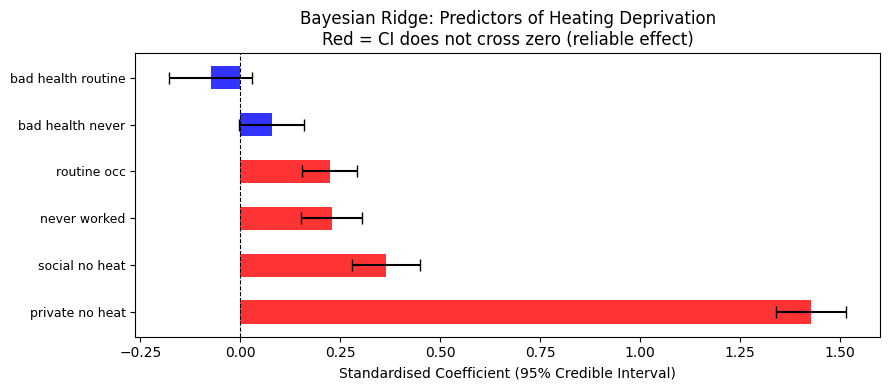

Saved: bayesian_credible_intervals.png


In [18]:
predictors = [
    'pct_routine_occ_2011',
    'pct_never_worked_2011',
    'pct_bad_health_routine_2011',
    'pct_bad_health_never_2011',
    'pct_social_no_heat_2011',
    'pct_private_no_heat_2011',
]
predictors = [p for p in predictors if p in x_imputed.columns]
outcome    = 'pct_no_heat_2011'

x2 = x_imputed[predictors].values
y2 = x_imputed[outcome].values

scaler_b2 = StandardScaler()
x2_sc   = scaler_b2.fit_transform(x2)

br = BayesianRidge(compute_score=True)
br.fit(x2_sc, y2)

coef_mean = br.coef_
coef_std  = np.sqrt(np.diag(br.sigma_))
ci_lower  = coef_mean - 1.96 * coef_std
ci_upper  = coef_mean + 1.96 * coef_std

credible_df = pd.DataFrame({
    'predictor':   predictors,
    'coef_mean':   coef_mean.round(4),
    'coef_std':    coef_std.round(4),
    'ci_lower_95': ci_lower.round(4),
    'ci_upper_95': ci_upper.round(4),
    'significant': ((ci_lower > 0) | (ci_upper < 0))
}).sort_values('coef_mean', ascending=False)

credible_df.to_csv('credible_intervals.csv', index=False)
print(f'R^2 score: {br.score(x2_sc, y2):.3f}')
print('\n95% Credible Intervals — Predictors of % No Central Heating:')
print(credible_df.to_string(index=False))
print('\nSaved: credible_intervals.csv')

# plot
fig, ax = plt.subplots(figsize=(9, 4))
colours = ['Red' if s else 'Blue' for s in credible_df['significant']]
y_pos   = range(len(credible_df))
ax.barh(y_pos, credible_df['coef_mean'],
        xerr=1.96*credible_df['coef_std'],
        color=colours, alpha=0.8, capsize=4, height=0.5)
ax.axvline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_yticks(y_pos)
ax.set_yticklabels([p.replace('pct_','').replace('_2011','').replace('_',' ')
                    for p in credible_df['predictor']], fontsize=9)
ax.set_xlabel('Standardised Coefficient (95% Credible Interval)')
ax.set_title('Bayesian Ridge: Predictors of Heating Deprivation\n'
             'Red = CI does not cross zero (reliable effect)')
plt.tight_layout()
plt.savefig('bayesian_credible_intervals.png', dpi=150)
plt.show()
print('Saved: bayesian_credible_intervals.png')

---
**Bayesian Trend Prediction to 2031 (PyMC)**

Modeled % no-heating as a linear function of year (2011=0, 2021=1) across all LAs, then extrapolate to 2031 (year=2).
The posterior predictive distribution gives a 95% credible interval for 2031, communicating uncertainty more informative than a point forecast.

In [19]:
# Stack row 
rows_stack = []
for _, r in x_imputed.iterrows():
    rows_stack.append({'year_idx': 0, 'pct_no_heat': r['pct_no_heat_2011']})
    rows_stack.append({'year_idx': 1, 'pct_no_heat': r['pct_no_heat_2021']})

long_df = pd.DataFrame(rows_stack)
x_t = long_df[['year_idx']].values
y_t = long_df['pct_no_heat'].values

br_trend = BayesianRidge(compute_score=True)
br_trend.fit(x_t, y_t)

# Predict 2031 (year_idx = 2) with posterior variance
pred_2031_mean, pred_2031_std = br_trend.predict([[2]], return_std=True)
ci_lo = pred_2031_mean[0] - 1.96 * pred_2031_std[0]
ci_hi = pred_2031_mean[0] + 1.96 * pred_2031_std[0]

print(f'2011 mean: {y_t[x_t[:,0]==0].mean():.2f}%')
print(f'2021 mean: {y_t[x_t[:,0]==1].mean():.2f}%')
print(f'2031 predicted: {pred_2031_mean[0]:.2f}%')
print(f'95% credible interval: [{ci_lo:.2f}%, {ci_hi:.2f}%]')

pred_df = pd.DataFrame({
    'year': [2011, 2021, 2031],
    'mean_pct_no_heat': [round(y_t[x_t[:,0]==0].mean(),3),
                         round(y_t[x_t[:,0]==1].mean(),3),
                         round(pred_2031_mean[0],3)],
    'ci_lower_95': [None, None, round(ci_lo,3)],
    'ci_upper_95': [None, None, round(ci_hi,3)],
})
pred_df.to_csv('trend_prediction_2031.csv', index=False)
print('Saved: trend_prediction_2031.csv')

2011 mean: 2.62%
2021 mean: 1.44%
2031 predicted: 0.27%
95% credible interval: [-2.64%, 3.18%]
Saved: trend_prediction_2031.csv


Predicted % no heating in 2031:
  Mean:             0.27%
  95% CI:           [-2.64%, 3.18%]
  Change 2011→2021: -1.18%


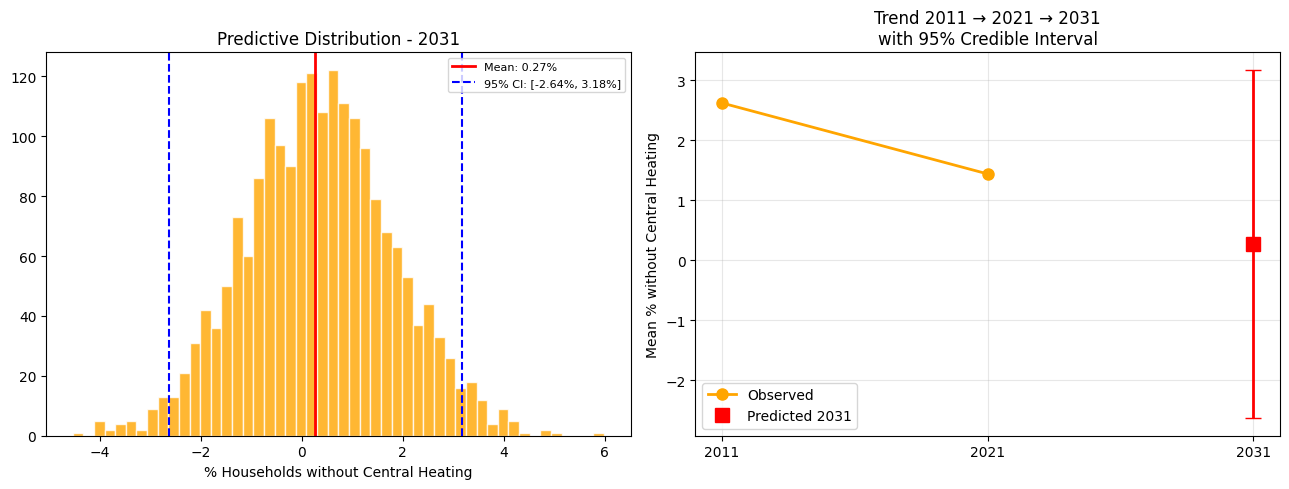

Saved: trend_prediction_2031.csv
Saved: bayesian_trend_prediction.png


In [21]:
# Plot and save trend prediction

mean_2031 = pred_2031_mean[0]
ci_lo     = mean_2031 - 1.96 * pred_2031_std[0]
ci_hi     = mean_2031 + 1.96 * pred_2031_std[0]

n_samples = 2000
np.random.seed(42)
pred_2031_samples = np.random.normal(
    loc   = pred_2031_mean[0],
    scale = pred_2031_std[0],
    size  = n_samples
)

print(f'Predicted % no heating in 2031:')
print(f'  Mean:             {mean_2031:.2f}%')
print(f'  95% CI:           [{ci_lo:.2f}%, {ci_hi:.2f}%]')
print(f'  Change 2011→2021: {y_t[x_t[:,0]==1].mean() - y_t[x_t[:,0]==0].mean():.2f}%')

# Save CSV
pred_df = pd.DataFrame({
    'year':             [2011, 2021, 2031],
    'mean_pct_no_heat': [round(y_t[x_t[:,0]==0].mean(), 3),
                         round(y_t[x_t[:,0]==1].mean(), 3),
                         round(mean_2031, 3)],
    'ci_lower_95':      [None, None, round(ci_lo, 3)],
    'ci_upper_95':      [None, None, round(ci_hi, 3)],
})
pred_df.to_csv('trend_prediction_2031.csv', index=False)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].hist(pred_2031_samples, bins=50, color='orange', alpha=0.8, edgecolor='white')
axes[0].axvline(mean_2031, color='red',    linewidth=2,
                label=f'Mean: {mean_2031:.2f}%')
axes[0].axvline(ci_lo,     color='blue', linewidth=1.5, linestyle='--')
axes[0].axvline(ci_hi,     color='blue', linewidth=1.5, linestyle='--',
                label=f'95% CI: [{ci_lo:.2f}%, {ci_hi:.2f}%]')
axes[0].set_xlabel('% Households without Central Heating')
axes[0].set_title('Predictive Distribution - 2031')
axes[0].legend(fontsize=8)

means_plot = [y_t[x_t[:,0]==0].mean(), y_t[x_t[:,0]==1].mean(), mean_2031]
axes[1].plot([2011, 2021], means_plot[:2], color='orange', marker='o',
             linewidth=2, markersize=8, label='Observed')
axes[1].plot(2031, mean_2031, 's', color='red', markersize=10, label='Predicted 2031')
axes[1].errorbar(2031, mean_2031,
                 yerr=[[mean_2031 - ci_lo], [ci_hi - mean_2031]],
                 fmt='none', color='red', capsize=6, linewidth=2)
axes[1].set_xticks([2011, 2021, 2031])
axes[1].set_ylabel('Mean % without Central Heating')
axes[1].set_title('Trend 2011 → 2021 → 2031\nwith 95% Credible Interval')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('bayesian_trend_prediction.png', dpi=150)
plt.show()
print('Saved: trend_prediction_2031.csv')
print('Saved: bayesian_trend_prediction.png')

----
**Bayesian Health Regression**

R^2 score: 0.697

Posterior coefficients — Predictors of Bad Health:
                 predictor  posterior_mean  posterior_std  ci_lower_95  ci_upper_95  significant
      pct_routine_occ_2011          1.2037         0.0671       1.0722       1.3351         True
     pct_never_worked_2011          0.7494         0.0660       0.6201       0.8787         True
  pct_private_no_heat_2011          0.5954         0.1755       0.2514       0.9393         True
        pct_with_heat_2011          0.3638         0.5902      -0.7930       1.5207        False
pct_no_heat_age_50_64_2011          0.2109         0.3836      -0.5411       0.9628        False
          pct_no_heat_2011         -0.3638         0.5902      -1.5207       0.7930        False

Interpretation:
  routine occ: INCREASES bad health — reliable effect
  never worked: INCREASES bad health — reliable effect
  private no heat: INCREASES bad health — reliable effect
  with heat: INCREASES bad health — uncertain
  no heat age 50 64: I

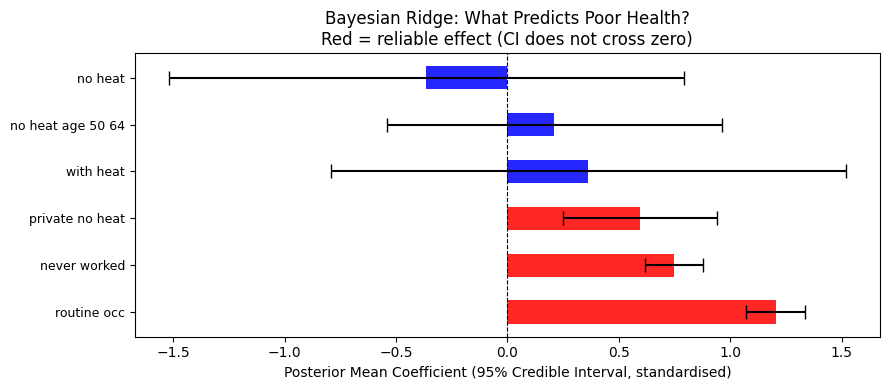

Saved: health_regression_coefficients.csv
Saved: bayesian_health_regression.png


In [22]:

health_pred = [
    'pct_no_heat_age_50_64_2011',
    'pct_private_no_heat_2011',
    'pct_routine_occ_2011',
    'pct_never_worked_2011',
    'pct_no_heat_2011',
    'pct_with_heat_2011',
]
health_pred   = [p for p in health_pred if p in x_imputed.columns]
health_outcome = 'pct_bad_health_2011'

df_3    = x_imputed[health_pred + [health_outcome]].dropna()
x_3_raw = df_3[health_pred].values
y_3     = df_3[health_outcome].values

scaler_b4 = StandardScaler()
x_3      = scaler_b4.fit_transform(x_3_raw)

br_health = BayesianRidge(compute_score=True)
br_health.fit(x_3, y_3)

# Extract posterior coefficients and credible intervals
coef_mean = br_health.coef_
coef_std  = np.sqrt(np.diag(br_health.sigma_))
ci_lower  = coef_mean - 1.96 * coef_std
ci_upper  = coef_mean + 1.96 * coef_std

health_coef = pd.DataFrame({
    'predictor':      health_pred,
    'posterior_mean': coef_mean.round(4),
    'posterior_std':  coef_std.round(4),
    'ci_lower_95':    ci_lower.round(4),
    'ci_upper_95':    ci_upper.round(4),
    'significant':    ((ci_lower > 0) | (ci_upper < 0))
}).sort_values('posterior_mean', ascending=False)

health_coef.to_csv('health_regression_coefficients.csv', index=False)

print(f'R^2 score: {br_health.score(x_3, y_3):.3f}')
print(f'\nPosterior coefficients — Predictors of Bad Health:')
print(health_coef.to_string(index=False))
print('\nInterpretation:')
for _, row in health_coef.iterrows():
    direction = 'INCREASES' if row['posterior_mean'] > 0 else 'DECREASES'
    cert = 'reliable effect' if row['significant'] else 'uncertain'
    name = row['predictor'].replace('pct_','').replace('_2011','').replace('_',' ')
    print(f'  {name}: {direction} bad health — {cert}')

# plot
fig, ax = plt.subplots(figsize=(9, 4))
colours = ['red' if s else 'blue' for s in health_coef['significant']]
y_pos   = range(len(health_coef))
ax.barh(y_pos, health_coef['posterior_mean'],
        xerr=1.96 * health_coef['posterior_std'],
        color=colours, alpha=0.85, capsize=5, height=0.5)
ax.axvline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_yticks(y_pos)
ax.set_yticklabels([p.replace('pct_','').replace('_2011','').replace('_',' ')
                    for p in health_coef['predictor']], fontsize=9)
ax.set_xlabel('Posterior Mean Coefficient (95% Credible Interval, standardised)')
ax.set_title('Bayesian Ridge: What Predicts Poor Health?\n'
             'Red = reliable effect (CI does not cross zero)')
plt.tight_layout()
plt.savefig('bayesian_health_regression.png', dpi=150)
plt.show()
print('Saved: health_regression_coefficients.csv')
print('Saved: bayesian_health_regression.png')

## 8. Standardise Features

In [23]:
# 2011 features only for dimensionality reduction
dr_cols = [
    'pct_no_heat_2011',
    'pct_no_heat_age_35_49_2011',
    'pct_no_heat_age_50_64_2011',
    'pct_no_heat_age_65plus_2011',
    'pct_social_no_heat_2011',
    'pct_private_no_heat_2011',
    'pct_bad_health_2011',
    'pct_routine_occ_2011',
    'pct_bad_health_routine_2011',
    'pct_never_worked_2011',
    'pct_bad_health_never_2011',
]
dr_cols = [c for c in dr_cols if c in x_imputed.columns]

x_dr     = x_imputed[dr_cols].values
scaler   = StandardScaler()
x_scaled = scaler.fit_transform(x_dr)

print(f'DR feature matrix shape: {x_scaled.shape}')
print(f'Features used ({len(dr_cols)}):')
print(dr_cols)
print(f'\nMean (should be ~0): {x_scaled.mean(axis=0).round(3)}')
print(f'Std  (should be ~1): {x_scaled.std(axis=0).round(3)}')

DR feature matrix shape: (331, 11)
Features used (11):
['pct_no_heat_2011', 'pct_no_heat_age_35_49_2011', 'pct_no_heat_age_50_64_2011', 'pct_no_heat_age_65plus_2011', 'pct_social_no_heat_2011', 'pct_private_no_heat_2011', 'pct_bad_health_2011', 'pct_routine_occ_2011', 'pct_bad_health_routine_2011', 'pct_never_worked_2011', 'pct_bad_health_never_2011']

Mean (should be ~0): [ 0.  0. -0.  0.  0. -0.  0.  0. -0.  0. -0.]
Std  (should be ~1): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 9. PCA

Variance explained per component:
  PC1: 49.2%  cumulative: 49.2%
  PC2: 30.2%  cumulative: 79.4%
  PC3: 7.2%  cumulative: 86.6%
  PC4: 6.6%  cumulative: 93.2%
  PC5: 2.9%  cumulative: 96.1%
  PC6: 1.8%  cumulative: 97.9%
  PC7: 1.3%  cumulative: 99.2%
  PC8: 0.4%  cumulative: 99.6%

2D variance: PC1=49.2%, PC2=30.2%

Top 5 variables loading onto PC1:
pct_no_heat_2011               0.426839
pct_no_heat_age_35_49_2011     0.422027
pct_no_heat_age_50_64_2011     0.421681
pct_no_heat_age_65plus_2011    0.405650
pct_private_no_heat_2011       0.399965
Name: PC1, dtype: float64

Top 5 variables loading onto PC2:
pct_bad_health_2011            0.529948
pct_bad_health_routine_2011    0.508648
pct_routine_occ_2011           0.403870
pct_never_worked_2011          0.376712
pct_bad_health_never_2011      0.368712
Name: PC2, dtype: float64


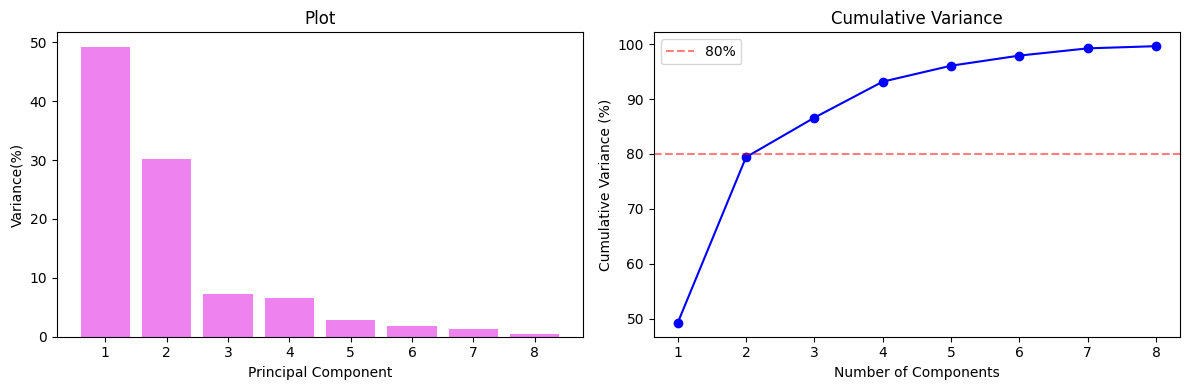


Saved: pca.png
Saved: pca_projection.csv


In [24]:
# PCA for scree plot
pca_full = PCA(random_state=42)
pca_full.fit(x_scaled)
cumvar = np.cumsum(pca_full.explained_variance_ratio_)

print('Variance explained per component:')
for i,(v,c) in enumerate(zip(pca_full.explained_variance_ratio_[:8], cumvar[:8])):
    print(f'  PC{i+1}: {v*100:.1f}%  cumulative: {c*100:.1f}%')

# 2D PCA for Tableau
pca   = PCA(n_components=2, random_state=42)
pca_r = pca.fit_transform(x_scaled)
print(f'\n2D variance: PC1={pca.explained_variance_ratio_[0]*100:.1f}%,'
      f' PC2={pca.explained_variance_ratio_[1]*100:.1f}%')

# what drives each PC
loadings = pd.DataFrame(pca.components_.T, index=dr_cols, columns=['PC1','PC2'])
print('\nTop 5 variables loading onto PC1:')
print(loadings['PC1'].abs().sort_values(ascending=False).head(5))
print('\nTop 5 variables loading onto PC2:')
print(loadings['PC2'].abs().sort_values(ascending=False).head(5))

# Scree plot
fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].bar(range(1,9), pca_full.explained_variance_ratio_[:8]*100, color='violet')
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Variance(%)')
axes[0].set_title('Plot')
axes[1].plot(range(1,9), cumvar[:8]*100, 'o-', color='blue')
axes[1].axhline(80, color='red', linestyle='--', alpha=0.5, label='80%')
axes[1].set_xlabel('Number of Components')
axes[1].set_ylabel('Cumulative Variance (%)')
axes[1].set_title('Cumulative Variance')
axes[1].legend()
plt.tight_layout()
plt.savefig('pca.png', dpi=150)
plt.show()

# Save for Tableau
pca_df = pd.DataFrame({'la_code': x_imputed['la_code'],
                        'la_name': x_imputed['la_name'],
                        'PC1': pca_r[:,0], 'PC2': pca_r[:,1]})
for col in ['pct_no_heat_2011','pct_bad_health_2011','pct_routine_occ_2011', 'pct_private_no_heat_2011'
            'pct_social_no_heat_2011', 'pct_no_heat_age_50_64_2011', 'pct_no_heat_age_65plus_2011',
            'pct_no_heat_2021','pct_bad_health_2021','harmonised']:
    if col in x_imputed.columns:
        pca_df[col] = x_imputed[col].values
pca_df.to_csv('pca_projection.csv', index=False)
print('\nSaved: pca.png')
print('Saved: pca_projection.csv')

-----------
**K-Means Cluster Evaluation - Find Optimal K**
* Finding Optimal K so that we can perform K-means clustering which could be used in visualisation.

In [32]:
# Test K=2,4,6,8,10 on PCA projection
pca_proj = pd.read_csv('pca_projection.csv')
X = pca_proj[['PC1', 'PC2']].values

K_range = range(2, 11, 2) 
metrics = {
    'inertia': [],
    'silhouette': []
}

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X)
    
    # Compute metrics
    inertia = kmeans.inertia_
    sil = silhouette_score(X, labels)
    
    metrics['inertia'].append(inertia)
    metrics['silhouette'].append(sil)
    
    print(f"{k:2d} | {inertia:7.1f} | {sil:10.3f}")

# Find best K by each metric
best_k_sil = K_range[np.argmax(metrics['silhouette'])] 




 2 |  1998.0 |      0.896
 4 |   729.8 |      0.450
 6 |   464.4 |      0.374
 8 |   315.0 |      0.405
10 |   255.5 |      0.354


## 10. t-SNE

Running t-SNE... 
t-SNE complete. KL divergence: 0.612


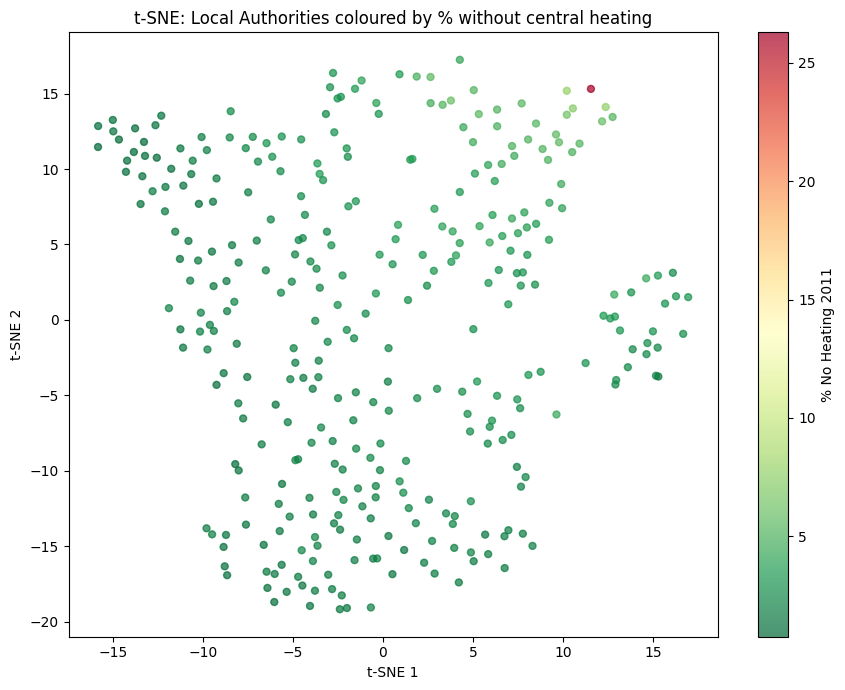

Saved: tsne_plot.png
Saved: tsne_projection.csv


In [29]:
print('Running t-SNE... ')

tsne   = TSNE(n_components=2, perplexity=30, n_iter=1000,
              random_state=42, learning_rate='auto', init='pca')
tsne_r = tsne.fit_transform(x_scaled)

print(f't-SNE complete. KL divergence: {tsne.kl_divergence_:.3f}')

# Quick plot
fig, ax = plt.subplots(figsize=(9,7))
sc = ax.scatter(tsne_r[:,0], tsne_r[:,1],
                c=x_imputed['pct_no_heat_2011'].values,
                cmap='RdYlGn_r', alpha=0.7, s=25)
plt.colorbar(sc, label='% No Heating 2011')
ax.set_title('t-SNE: Local Authorities coloured by % without central heating')
ax.set_xlabel('t-SNE 1')
ax.set_ylabel('t-SNE 2')
plt.tight_layout()
plt.savefig('tsne_plot.png', dpi=150)
plt.show()

# Save for Tableau
tsne_df = pd.DataFrame({'la_code': x_imputed['la_code'],
                         'la_name': x_imputed['la_name'],
                         'tSNE1': tsne_r[:,0], 'tSNE2': tsne_r[:,1]})
for col in ['pct_no_heat_2011','pct_bad_health_2011','pct_routine_occ_2011', 'pct_private_no_heat_2011'
            'pct_social_no_heat_2011', 'pct_no_heat_age_50_64_2011', 'pct_no_heat_age_65plus_2011',
            'pct_no_heat_2021','pct_bad_health_2021','harmonised']:
    if col in x_imputed.columns:
        tsne_df[col] = x_imputed[col].values
tsne_df.to_csv('tsne_projection.csv', index=False)
print('Saved: tsne_plot.png')
print('Saved: tsne_projection.csv')

## 11. MDS (Metric)

Directly answers which LAs are most similar overall by perserving actual Eucleadian distance. Unlike t-SNE/UMAP (topological), MDS is metric: distances in the plot approximate original high-dimensional distances. Best for comparing.


In [30]:
print('Running MDS... ')

mds   = MDS(n_components=2, metric=True, n_init=4,
            max_iter=300, random_state=42, n_jobs=-1)
mds_r = mds.fit_transform(x_scaled)

print(f'MDS complete. Stress: {mds.stress_:.1f} (lower = better fit)')

mds_df = pd.DataFrame({'la_code': x_imputed['la_code'],
                        'la_name': x_imputed['la_name'],
                        'MDS1': mds_r[:,0], 'MDS2': mds_r[:,1]})
for col in ['pct_no_heat_2011','pct_bad_health_2011','pct_routine_occ_2011', 'pct_private_no_heat_2011'
            'pct_social_no_heat_2011', 'pct_no_heat_age_50_64_2011', 'pct_no_heat_age_65plus_2011',
            'pct_no_heat_2021','pct_bad_health_2021','harmonised']:
    if col in x_imputed.columns:
        mds_df[col] = x_imputed[col].values
print(f'MDS complete. Shape: {mds_r.shape}')
mds_df.to_csv('mds_projection.csv', index=False)
print('Saved: mds_projection.csv')

Running MDS... 
MDS complete. Stress: 29839.4 (lower = better fit)
MDS complete. Shape: (331, 2)
Saved: mds_projection.csv


---------
**Performing clustering for K-mean Clustering for k=4.**

In [31]:

n_clusters = 4 # Based on previous evaluation k =2 performed well, but 4, the next best as it is more interpretable.

# PCA clusters
pca_proj = pd.read_csv('pca_projection.csv')
kmeans_pca = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
pca_proj['cluster'] = kmeans_pca.fit_predict(pca_proj[['PC1','PC2']])
pca_proj.to_csv('pca_projection.csv', index=False)
print(f'PCA clusters: {pca_proj["cluster"].value_counts().sort_index().to_dict()}')

# t-SNE clusters
tsne_proj = pd.read_csv('tsne_projection.csv')
kmeans_tsne = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
tsne_proj['cluster'] = kmeans_tsne.fit_predict(tsne_proj[['tSNE1','tSNE2']])
tsne_proj.to_csv('tsne_projection.csv', index=False)
print(f't-SNE clusters: {tsne_proj["cluster"].value_counts().sort_index().to_dict()}')

# MDS clusters
mds_proj = pd.read_csv('mds_projection.csv')
kmeans_mds = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
mds_proj['cluster'] = kmeans_mds.fit_predict(mds_proj[['MDS1','MDS2']])
mds_proj.to_csv('mds_projection.csv', index=False)
print(f'MDS clusters: {mds_proj["cluster"].value_counts().sort_index().to_dict()}')

print('\nAll projection files updated with cluster labels (0-3)')

PCA clusters: {0: 74, 1: 179, 2: 77, 3: 1}
t-SNE clusters: {0: 106, 1: 93, 2: 53, 3: 79}
MDS clusters: {0: 88, 1: 1, 2: 168, 3: 74}

All projection files updated with cluster labels (0-3)


## 12. Exporting the final dataset and Summary

In [28]:
# FINAL EXPORT — all files for Tableau

# Verify no placeholder codes remain
print(f"HARMONISED placeholders: {(x_imputed['la_code']=='HARMONISED').sum()}")

# Add change columns
x_imputed['change_no_heat_2011_2021']    = x_imputed['pct_no_heat_2021'] - x_imputed['pct_no_heat_2011']
x_imputed['change_bad_health_2011_2021'] = x_imputed['pct_bad_health_2021'] - x_imputed['pct_bad_health_2011']

# Export master dataset (331 rows, 2021 boundaries)
x_imputed.to_csv('master_dataset.csv', index=False)
print(f'✓ master_dataset.csv exported: {x_imputed.shape[0]} rows × {x_imputed.shape[1]} columns')

# Verify projection files exist (created in DR cells above)
print('\nProjection files:')
for fname in ['pca_projection.csv', 'tsne_projection.csv', 'mds_projection.csv']:
    try:
        df = pd.read_csv(fname)
        print(f'{fname}: {df.shape[0]} rows × {df.shape[1]} columns')
    except:
        print(f'{fname}: NOT FOUND (run DR cells above)')

# Verify Bayesian outputs exist
print('\nBayesian outputs:')
for fname in ['credible_intervals.csv', 'trend_prediction_2031.csv',
              'health_regression_coefficients.csv']:
    try:
        df = pd.read_csv(fname)
        print(f'{fname}: {df.shape[0]} rows')
    except:
        print(f'{fname}: NOT FOUND (run Bayesian cells above)')

# Verify 2011 dataset exists (created in Cell 15)
print('\n2011 dataset (348 rows, 2011 boundaries):')
try:
    d2011 = pd.read_csv('data_2011_348_clean.csv')
    print(f'data_2011_348_clean.csv: {len(d2011)} rows × {len(d2011.columns)} columns')
    print(f'     Use for: maps with hyper file (zero patches)')
except:
    print('data_2011_348_clean.csv: NOT FOUND (run Cell 15)')

print('\n' + '-' * 60)
print('SUMMARY')
print('-' * 60)
print(f'Master dataset (331 rows, 2021 boundaries):')
print(f'  - Directly matched 2021 data:  {(master_final["harmonised"]==False).sum()} LAs')
print(f'  - Harmonised (aggregated 2011): {(master_final["harmonised"]==True).sum()} LAs')
print(f'  - Missing 2021 values (imputed): {master_final["pct_no_heat_2021"].isna().sum()} LAs')
print(f'  - Total features: {x_imputed.shape[1]}')

print(f'\nDimensionality reduction projections: 3 files (PCA, t-SNE, MDS)')
print(f'  - Each: {x_imputed.shape[0]} rows')
print(f'  - Use for: Dashboard 2 (DR Explorer)')

print(f'\nBayesian outputs: 3 files')
print(f'  - Credible intervals, trend prediction, health regression')

print(f'\n2011 dataset: 348 rows (original 2011 boundaries)')
print(f'  - Use for: Dashboard 1 maps with hyper file')

print(f'\nBayesian trend prediction for 2031: {pred_df.loc[2, "mean_pct_no_heat"]:.2f}% no heating')
print('\nAll files ready for Tableau')

HARMONISED placeholders: 0
✓ master_dataset.csv exported: 331 rows × 31 columns

Projection files:
pca_projection.csv: 331 rows × 12 columns
tsne_projection.csv: 331 rows × 12 columns
mds_projection.csv: 331 rows × 12 columns

Bayesian outputs:
credible_intervals.csv: 6 rows
trend_prediction_2031.csv: 3 rows
health_regression_coefficients.csv: 6 rows

2011 dataset (348 rows, 2011 boundaries):
data_2011_348_clean.csv: 348 rows × 23 columns
     Use for: maps with hyper file (zero patches)

------------------------------------------------------------
SUMMARY
------------------------------------------------------------
Master dataset (331 rows, 2021 boundaries):
  - Directly matched 2021 data:  323 LAs
  - Harmonised (aggregated 2011): 8 LAs
  - Missing 2021 values (imputed): 0 LAs
  - Total features: 31

Dimensionality reduction projections: 3 files (PCA, t-SNE, MDS)
  - Each: 331 rows
  - Use for: Dashboard 2 (DR Explorer)

Bayesian outputs: 3 files
  - Credible intervals, trend predict

In [38]:
# FINAL STEP: Create the hybrid dataset for Tableau maps with tooltips
# This dataset combines the original 2011 boundaries (for mapping) with the new 2021 data (for tooltips).
# The 25 merged LAs will have their 2021 values imputed using Bayesian Ridge Regression, and their names/codes updated to reflect the new Unitary Authorities.

# 1. Load the datasets
df_2011 = pd.read_csv('data_2011_348_clean.csv')
df_master = pd.read_csv('master_dataset.csv')

# 2. Prep master dataset for merging
# We ONLY want to bring over the 2021 columns to prevent '_x' and '_y' duplicates
cols_2021 = [c for c in df_master.columns if '2021' in c]
df_master_subset = df_master[['la_name', 'la_code'] + cols_2021].copy()

# Rename the 2021 code column so we don't confuse it with the 2011 code
df_master_subset.rename(columns={'la_code': 'la_code_2021'}, inplace=True)

# 3. Join on LA_NAME
hybrid_df = pd.merge(df_2011, df_master_subset, on='la_name', how='left')

# Duplicate the name column so we have a dedicated 2021 name column for the tooltip
hybrid_df['la_name_2021'] = hybrid_df['la_name']

# 4. Set up Bayesian Ridge Regression
missing_mask = hybrid_df[cols_2021[0]].isna()
train_df = hybrid_df[~missing_mask]
predict_df = hybrid_df[missing_mask]

print(f"Found {len(train_df)} LAs with complete 2021 data (Training Set - 323 expected)")
print(f"Found {len(predict_df)} merged LAs missing 2021 data (Imputation Set - 25 expected)\n")

# Get numeric 2011 features to act as predictors
features_2011 = [c for c in df_2011.columns if '2011' in c and pd.api.types.is_numeric_dtype(df_2011[c])]

# Scale the predictors
scaler = StandardScaler()
X_train = scaler.fit_transform(train_df[features_2011])
X_predict = scaler.transform(predict_df[features_2011])

# 5. Run the model to predict the 25 missing values
print("Predicting missing 2021 values for the 25 merged LAs...")
for col in cols_2021:
    y_train = train_df[col]
    model = BayesianRidge()
    model.fit(X_train, y_train)
    preds = model.predict(X_predict)
    hybrid_df.loc[missing_mask, col] = preds

# 6. Apply your Boundary Map for the Tooltips
boundary_map = {
    'buckinghamshire':                    ['aylesbury vale', 'chiltern', 'south bucks', 'wycombe'],
    'north northamptonshire':             ['corby', 'east northamptonshire', 'kettering', 'wellingborough'],
    'west northamptonshire':              ['daventry', 'northampton', 'south northamptonshire'],
    'west suffolk':                       ['forest heath', 'st edmundsbury'],
    'east suffolk':                       ['suffolk coastal', 'waveney'],
    'bournemouth christchurch and poole': ['bournemouth', 'poole', 'christchurch'],
    'dorset':                             ['east dorset', 'north dorset', 'purbeck', 'west dorset', 'weymouth and portland'],
    'somerset west and taunton':          ['taunton deane', 'west somerset']
}

# Create a lookup dictionary from the master dataset to grab proper casing and new codes
master_lookup = {row['la_name'].lower(): (row['la_name'], row['la_code']) 
                 for _, row in df_master.iterrows()}

# Update the 25 imputed rows with their new 2021 Unitary names and codes
for idx in hybrid_df[missing_mask].index:
    old_name = hybrid_df.loc[idx, 'la_name'].lower()
    
    # Find which new Unitary Authority this old LA belongs to
    for new_unitary, old_las in boundary_map.items():
        if old_name in old_las:
            # Grab the proper capitalized name and the new code from our lookup
            proper_new_name, new_code = master_lookup[new_unitary]
            
            hybrid_df.loc[idx, 'la_name_2021'] = proper_new_name
            hybrid_df.loc[idx, 'la_code_2021'] = new_code
            break

# 7. Format exactly for Tableau Custom Geocoding Map
# Rename the 2011 boundary columns to match the .tds file
hybrid_df.rename(columns={
    'la_code': 'la_code_2011', 
    'la_name': 'la_name_2011'
}, inplace=True)

# Rearrange columns so the map codes and tooltip codes are at the front
front_cols = ['la_code_2011', 'la_name_2011', 'la_code_2021', 'la_name_2021']
other_cols = [c for c in hybrid_df.columns if c not in front_cols]
hybrid_df = hybrid_df[front_cols + other_cols]

# 8. Export
export_name = 'hybrid_tableau_dataset_optimized.csv'
hybrid_df.to_csv(export_name, index=False)

print(f"Exported: {export_name}")
print(f"Final Shape: {hybrid_df.shape[0]} rows × {hybrid_df.shape[1]} columns")



Found 323 LAs with complete 2021 data (Training Set - 323 expected)
Found 25 merged LAs missing 2021 data (Imputation Set - 25 expected)

Predicting missing 2021 values for the 25 merged LAs...
Exported: hybrid_tableau_dataset_optimized.csv
Final Shape: 348 rows × 31 columns
